# Phase 1 -- Baseline Models
## AI-Based Disaster Preparedness Assistant: Cyclone Preparedness Index

---

**Experiment Tracking**: Weights & Biases (wandb)  
**Models**: Ridge Regression · Random Forest · HistGradientBoosting  
**Targets**:  
- `preparedness_score` (continuous regression, 0-100)  
- `preparedness_tier` (3-class: Low / Medium / High)  

**Splits Compared**: 60/20/20 · 70/15/15 · 80/10/10 (random + spatial block)


## 0. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

# Sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_val_score
from sklearn.preprocessing import RobustScaler, LabelEncoder, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, f1_score, classification_report,
    confusion_matrix, roc_auc_score, roc_curve, ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance

# W&B
import wandb

# Plot config
plt.rcParams.update({
    "figure.dpi": 130, "figure.facecolor": "#0f1117",
    "axes.facecolor": "#1a1d27", "axes.edgecolor": "#3a3d4f",
    "axes.labelcolor": "#e0e0e0", "text.color": "#e0e0e0",
    "xtick.color": "#b0b0b0", "ytick.color": "#b0b0b0",
    "grid.color": "#2a2d3a", "grid.linewidth": 0.5,
    "axes.titlesize": 12, "axes.labelsize": 10,
    "legend.facecolor": "#1a1d27", "legend.edgecolor": "#3a3d4f",
})

TIER_COLORS = {"Low":"#EF5350","Medium":"#FFA726","High":"#66BB6A"}
MODEL_COLORS = {"Ridge":"#4FC3F7","RandomForest":"#81C784","HistGBT":"#FFB74D"}


In [2]:
# Load modelling dataset
df = pd.read_parquet("../data/processed/modelling_dataset.parquet")
print(f"Dataset: {df.shape[0]:,} villages × {df.shape[1]} columns")

MODEL_FEATURES = [c for c in df.columns if c not in
    ["area_id","village_code","village_name","district_name",
     "preparedness_score","preparedness_tier","tauktae_affected"]]

X = df[MODEL_FEATURES].copy()
y_reg = df["preparedness_score"].copy()
y_cls = df["preparedness_tier"].astype(str).copy()

le = LabelEncoder()
y_cls_enc = le.fit_transform(y_cls)
print(f"\nModel Features: {len(MODEL_FEATURES)}")
print(f"Regression target range: {y_reg.min():.1f} - {y_reg.max():.1f}  (mean={y_reg.mean():.2f})")
print(f"\nClassification target distribution:")
print(pd.Series(y_cls).value_counts().to_string())
print(f"\nClass encoding: {dict(zip(le.classes_, range(len(le.classes_))))}")


Dataset: 1,879 villages × 33 columns

Model Features: 26
Regression target range: 20.1 - 81.5  (mean=54.24)

Classification target distribution:
preparedness_tier
Medium    1128
High       596
Low        155

Class encoding: {'High': 0, 'Low': 1, 'Medium': 2}


## 1. Weights & Biases -- Experiment Tracking Setup

In [3]:
# Initialize W&B project
# Automatically switches between online (if WANDB_API_KEY set) and offline (local tracking in ./wandb)
WANDB_PROJECT = "cyclone-preparedness-karnataka"
WANDB_ENTITY  = None  # Set to your W&B username / team name if needed
WANDB_MODE    = "online" if os.environ.get("WANDB_API_KEY") else "offline"

if WANDB_MODE == "offline":
    os.environ["WANDB_MODE"] = "offline"
    print("Weights & Biases running in OFFLINE mode (runs saved locally to ./wandb).")
    print("To sync to wandb.ai later, set WANDB_API_KEY or run `wandb login` then `wandb sync wandb/latest-run`.")
else:
    print("Weights & Biases connected ONLINE!")

print("W&B Project:", WANDB_PROJECT)
print("Dashboard will track runs at: https://wandb.ai/home -> Projects ->", WANDB_PROJECT)


Weights & Biases running in OFFLINE mode (runs saved locally to ./wandb).
To sync to wandb.ai later, set WANDB_API_KEY or run `wandb login` then `wandb sync wandb/latest-run`.
W&B Project: cyclone-preparedness-karnataka
Dashboard will track runs at: https://wandb.ai/home -> Projects -> cyclone-preparedness-karnataka


## 2. Train / Validation / Test Splits

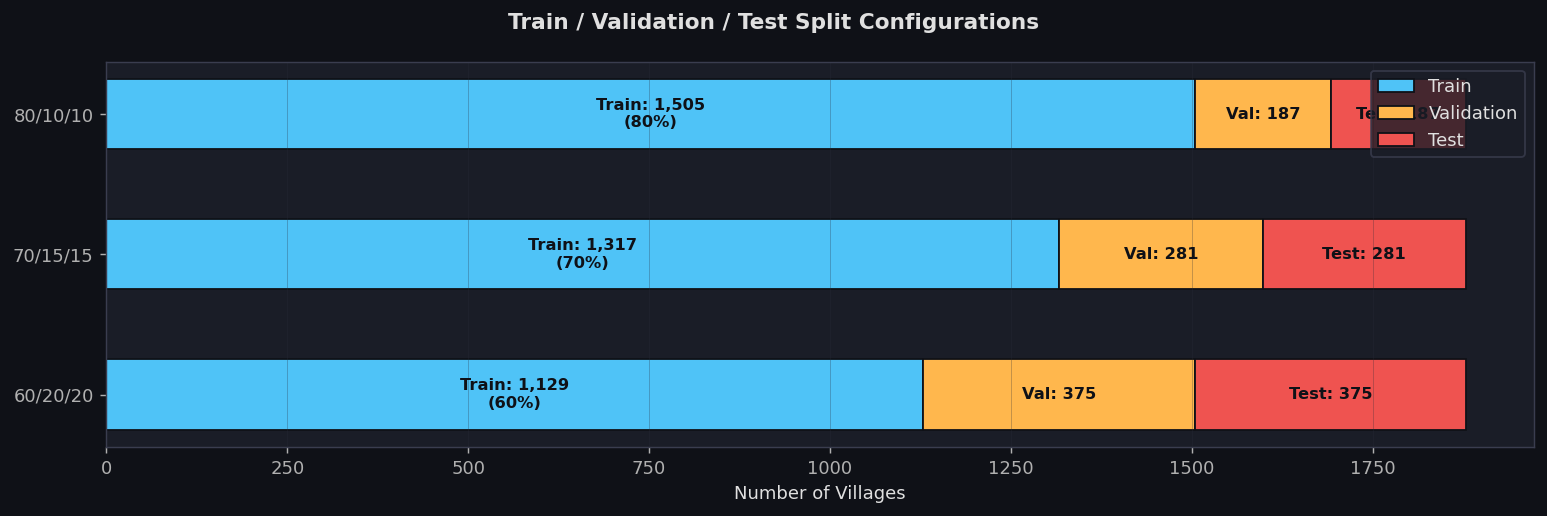

In [4]:
SPLIT_CONFIGS = {
    "split_60_20_20": dict(test_size=0.20, val_size=0.20, random_state=42),
    "split_70_15_15": dict(test_size=0.15, val_size=0.15, random_state=42),
    "split_80_10_10": dict(test_size=0.10, val_size=0.10, random_state=42),
}

def make_splits(X, y_reg, y_cls_enc, test_size, val_size, random_state):
    X_tmp, X_test, y_r_tmp, y_r_test, y_c_tmp, y_c_test = train_test_split(
        X, y_reg, y_cls_enc, test_size=test_size, stratify=y_cls_enc, random_state=random_state)
    
    val_frac = val_size / (1 - test_size)  # Adjust val fraction from remaining
    X_train, X_val, y_r_train, y_r_val, y_c_train, y_c_val = train_test_split(
        X_tmp, y_r_tmp, y_c_tmp, test_size=val_frac, stratify=y_c_tmp, random_state=random_state)
    
    return (X_train, X_val, X_test,
            y_r_train, y_r_val, y_r_test,
            y_c_train, y_c_val, y_c_test)

# Visualise split sizes
fig, ax = plt.subplots(figsize=(12, 4))
fig.suptitle("Train / Validation / Test Split Configurations", fontsize=12, fontweight="bold")

for i, (split_name, cfg) in enumerate(SPLIT_CONFIGS.items()):
    test_n  = int(len(df) * cfg["test_size"])
    val_n   = int(len(df) * cfg["val_size"])
    train_n = len(df) - test_n - val_n
    ax.barh(i, train_n, color="#4FC3F7", edgecolor="#0f1117", height=0.5, label="Train" if i==0 else "")
    ax.barh(i, val_n,   color="#FFB74D", edgecolor="#0f1117", height=0.5, left=train_n, label="Validation" if i==0 else "")
    ax.barh(i, test_n,  color="#EF5350", edgecolor="#0f1117", height=0.5, left=train_n+val_n, label="Test" if i==0 else "")
    ax.text(train_n/2, i, f"Train: {train_n:,}\n({train_n/len(df):.0%})",
            ha="center", va="center", fontsize=9, color="#0f1117", fontweight="bold")
    ax.text(train_n + val_n/2, i, f"Val: {val_n:,}",
            ha="center", va="center", fontsize=9, color="#0f1117", fontweight="bold")
    ax.text(train_n + val_n + test_n/2, i, f"Test: {test_n:,}",
            ha="center", va="center", fontsize=9, color="#0f1117", fontweight="bold")

ax.set_yticks(range(len(SPLIT_CONFIGS)))
ax.set_yticklabels(["60/20/20", "70/15/15", "80/10/10"])
ax.set_xlabel("Number of Villages")
ax.legend(loc="upper right")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("../notebooks/fig_11_splits.png", dpi=130, bbox_inches="tight", facecolor="#0f1117")
plt.show()


## 3. Model Definitions & Pipelines

In [5]:
def build_regression_models():
    return {
        "Ridge": Pipeline([
            ("scaler", RobustScaler()),
            ("model", Ridge(alpha=10.0))
        ]),
        "RandomForest": Pipeline([
            ("scaler", RobustScaler()),
            ("model", RandomForestRegressor(
                n_estimators=200, max_depth=12,
                min_samples_leaf=5, n_jobs=-1, random_state=42
            ))
        ]),
        "HistGBT": Pipeline([
            ("scaler", RobustScaler()),
            ("model", HistGradientBoostingRegressor(
                max_iter=200, max_depth=5,
                learning_rate=0.05, min_samples_leaf=20,
                random_state=42
            ))
        ]),
    }

def build_classification_models():
    return {
        "LogisticRegression": Pipeline([
            ("scaler", RobustScaler()),
            ("model", LogisticRegression(
                C=1.0, max_iter=500, multi_class="multinomial",
                solver="lbfgs", random_state=42
            ))
        ]),
        "RandomForest": Pipeline([
            ("scaler", RobustScaler()),
            ("model", RandomForestClassifier(
                n_estimators=200, max_depth=12,
                min_samples_leaf=5, n_jobs=-1, random_state=42
            ))
        ]),
        "HistGBT": Pipeline([
            ("scaler", RobustScaler()),
            ("model", HistGradientBoostingClassifier(
                max_iter=200, max_depth=5,
                learning_rate=0.05, min_samples_leaf=20,
                random_state=42
            ))
        ]),
    }

print("Regression models:", list(build_regression_models().keys()))
print("Classification models:", list(build_classification_models().keys()))


Regression models: ['Ridge', 'RandomForest', 'HistGBT']
Classification models: ['LogisticRegression', 'RandomForest', 'HistGBT']


## 4. Training Loop -- All Splits × All Models (with W&B Logging)

In [6]:
all_results = []

for split_name, cfg in SPLIT_CONFIGS.items():
    print(f"\n{'='*60}")
    print(f"SPLIT: {split_name}")
    print(f"{'='*60}")
    
    (X_train, X_val, X_test,
     y_r_train, y_r_val, y_r_test,
     y_c_train, y_c_val, y_c_test) = make_splits(X, y_reg, y_cls_enc, **cfg)
    
    # ── Regression ────────────────────────────────────────────────
    reg_models = build_regression_models()
    for model_name, pipeline in reg_models.items():
        run = wandb.init(
            project=WANDB_PROJECT,
            entity=WANDB_ENTITY,
            mode=WANDB_MODE,
            name=f"REG_{model_name}_{split_name}",
            group="regression",
            tags=["regression", model_name, split_name, "phase1"],
            config={
                "model": model_name,
                "split": split_name,
                "task": "regression",
                "target": "preparedness_score",
                "n_features": len(MODEL_FEATURES),
                "train_size": len(X_train),
                "val_size": len(X_val),
                "test_size": len(X_test),
                **cfg
            }
        )
        
        pipeline.fit(X_train, y_r_train)
        
        metrics = {}
        for split_label, X_s, y_s in [("train",X_train,y_r_train),("val",X_val,y_r_val),("test",X_test,y_r_test)]:
            y_pred = pipeline.predict(X_s)
            rmse = np.sqrt(mean_squared_error(y_s, y_pred))
            mae  = mean_absolute_error(y_s, y_pred)
            r2   = r2_score(y_s, y_pred)
            metrics.update({f"{split_label}_rmse": rmse, f"{split_label}_mae": mae, f"{split_label}_r2": r2})
        
        wandb.log(metrics)
        run.finish()
        
        all_results.append({
            "task": "regression", "split": split_name, "model": model_name, **metrics
        })
        print(f"  [REG] {model_name:20s} | Test RMSE={metrics['test_rmse']:.2f}  MAE={metrics['test_mae']:.2f}  R^2={metrics['test_r2']:.4f}")
    
    # ── Classification ────────────────────────────────────────────
    cls_models = build_classification_models()
    for model_name, pipeline in cls_models.items():
        run = wandb.init(
            project=WANDB_PROJECT,
            entity=WANDB_ENTITY,
            mode=WANDB_MODE,
            name=f"CLS_{model_name}_{split_name}",
            group="classification",
            tags=["classification", model_name, split_name, "phase1"],
            config={
                "model": model_name,
                "split": split_name,
                "task": "classification",
                "target": "preparedness_tier",
                "classes": list(le.classes_),
                "n_features": len(MODEL_FEATURES),
                "train_size": len(X_train),
            }
        )
        
        pipeline.fit(X_train, y_c_train)
        
        metrics = {}
        for split_label, X_s, y_s in [("train",X_train,y_c_train),("val",X_val,y_c_val),("test",X_test,y_c_test)]:
            y_pred = pipeline.predict(X_s)
            acc    = accuracy_score(y_s, y_pred)
            f1_mac = f1_score(y_s, y_pred, average="macro")
            f1_wtd = f1_score(y_s, y_pred, average="weighted")
            metrics.update({
                f"{split_label}_accuracy": acc,
                f"{split_label}_f1_macro": f1_mac,
                f"{split_label}_f1_weighted": f1_wtd,
            })
        
        wandb.log(metrics)
        run.finish()
        
        all_results.append({
            "task": "classification", "split": split_name, "model": model_name, **metrics
        })
        print(f"  [CLS] {model_name:20s} | Test Acc={metrics['test_accuracy']:.4f}  F1-mac={metrics['test_f1_macro']:.4f}")

results_df = pd.DataFrame(all_results)
results_df.to_csv("../data/processed/model_results.csv", index=False)
print("\nResults saved: data/processed/model_results.csv")



SPLIT: split_60_20_20


wandb: Tracking run with wandb version 0.31.0


wandb: W&B syncing is set to `offline` in this directory. Run `wandb online` or set WANDB_MODE=online to enable cloud syncing.
wandb: Run data is saved locally in C:\Users\Kanishk\Desktop\cyclone-preparedness\notebooks\wandb\offline-run-20261022_233346-t8oirjuc
wandb: View this run in the terminal with `wandb leet`


wandb: 
wandb: Run history:
wandb:   test_mae ▁
wandb:    test_r2 ▁
wandb:  test_rmse ▁
wandb:  train_mae ▁
wandb:   train_r2 ▁
wandb: train_rmse ▁
wandb:    val_mae ▁
wandb:     val_r2 ▁
wandb:   val_rmse ▁
wandb: 
wandb: Run summary:
wandb:   test_mae 1.21172
wandb:    test_r2 0.97674
wandb:  test_rmse 1.63872
wandb:  train_mae 1.25929
wandb:   train_r2 0.97584
wandb: train_rmse 1.65842
wandb:    val_mae 1.29967
wandb:     val_r2 0.97266
wandb:   val_rmse 1.79176
wandb: 


wandb: You can sync this run to the cloud by running:
wandb: wandb sync C:\Users\Kanishk\Desktop\cyclone-preparedness\notebooks\wandb\offline-run-20261022_233346-t8oirjuc


wandb: Find logs at: .\wandb\offline-run-20261022_233346-t8oirjuc\logs


... (99 outputs left out)

wandb: 
wandb: Run history:
wandb:     test_accuracy ▁
wandb:     test_f1_macro ▁
wandb:  test_f1_weighted ▁
wandb:    train_accuracy ▁
wandb:    train_f1_macro ▁
wandb: train_f1_weighted ▁
wandb:      val_accuracy ▁
wandb:      val_f1_macro ▁
wandb:   val_f1_weighted ▁
wandb: 
wandb: Run summary:
wandb:     test_accuracy 0.92021
wandb:     test_f1_macro 0.88866
wandb:  test_f1_weighted 0.91926
wandb:    train_accuracy 1
wandb:    train_f1_macro 1
wandb: train_f1_weighted 1
wandb:      val_accuracy 0.93617
wandb:      val_f1_macro 0.87611
wandb:   val_f1_weighted 0.93493
wandb: 


wandb: You can sync this run to the cloud by running:
wandb: wandb sync C:\Users\Kanishk\Desktop\cyclone-preparedness\notebooks\wandb\offline-run-20261022_233418-mxpc11nm


wandb: Find logs at: .\wandb\offline-run-20261022_233418-mxpc11nm\logs


  [CLS] HistGBT              | Test Acc=0.9202  F1-mac=0.8887

Results saved: data/processed/model_results.csv


## 5. Model Comparison Charts

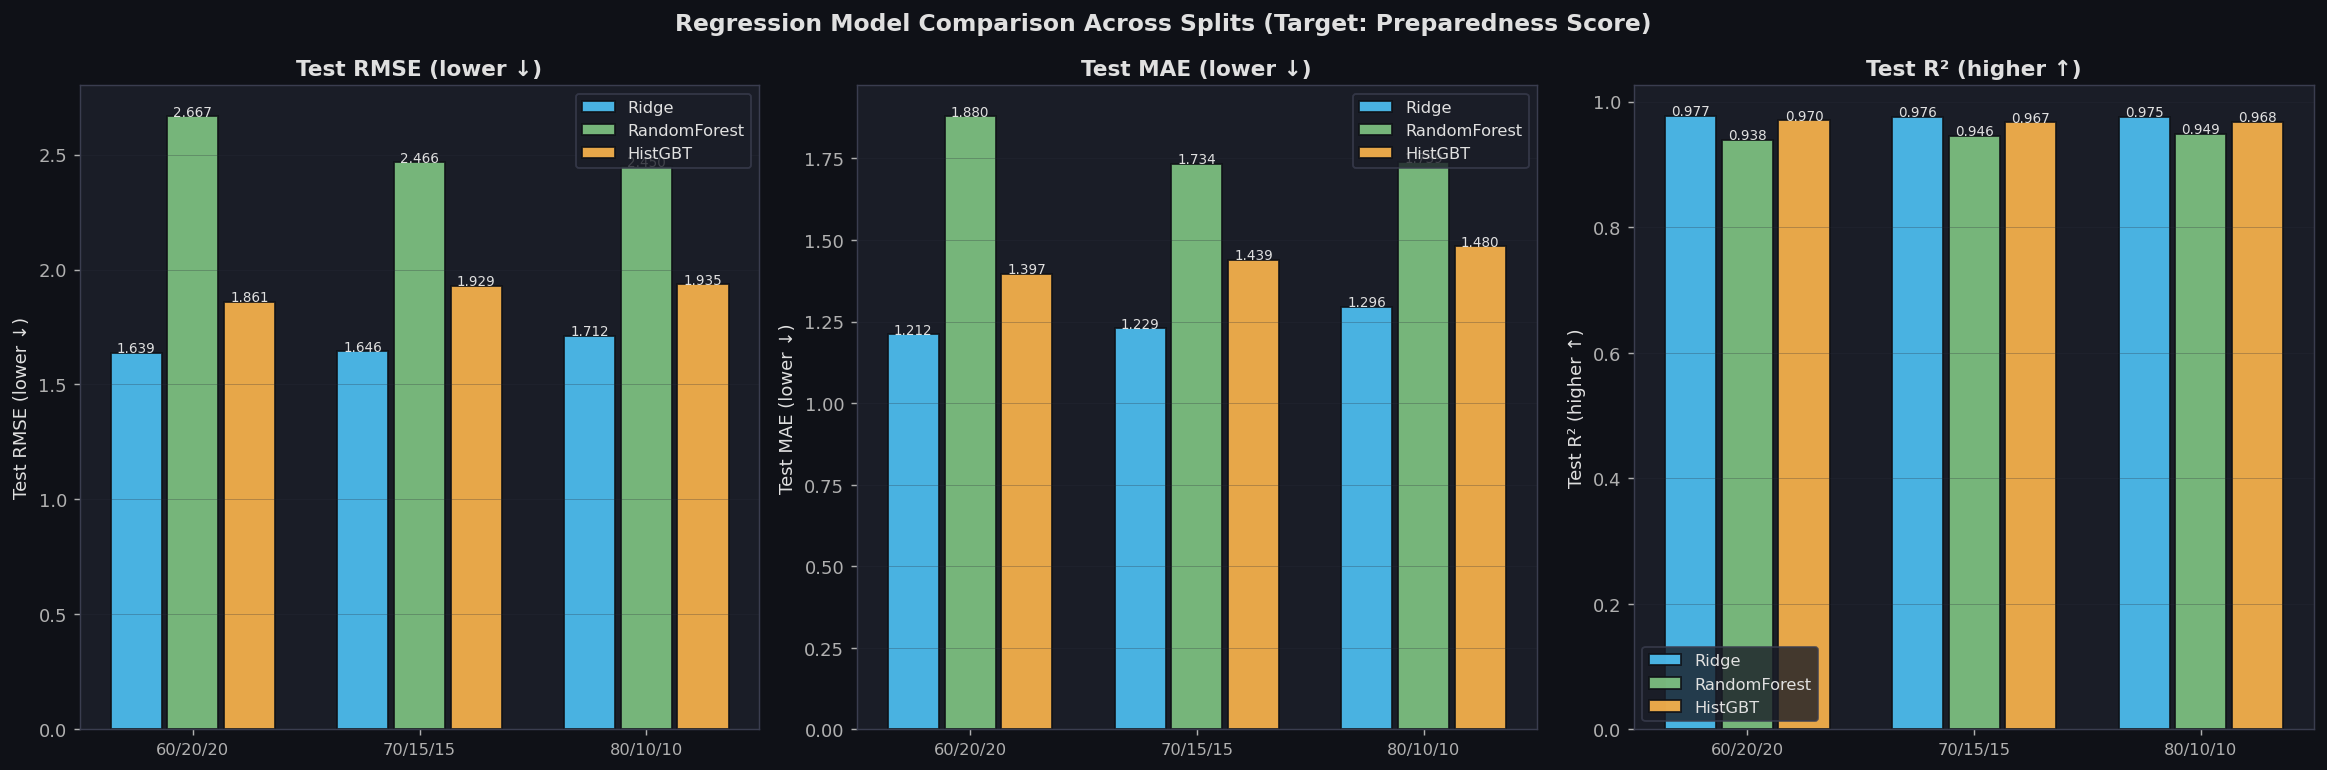

In [7]:
reg_res = results_df[results_df["task"]=="regression"].copy()
cls_res = results_df[results_df["task"]=="classification"].copy()

# ── Regression comparison ──
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("Regression Model Comparison Across Splits (Target: Preparedness Score)", fontsize=13, fontweight="bold")

metrics_reg = [
    ("test_rmse", "Test RMSE (lower ↓)", False),
    ("test_mae",  "Test MAE (lower ↓)",  False),
    ("test_r2",   "Test R² (higher ↑)",  True),
]

model_names_reg = ["Ridge","RandomForest","HistGBT"]
split_names     = ["split_60_20_20","split_70_15_15","split_80_10_10"]
x_positions = np.arange(len(split_names))
width = 0.25

for ax, (metric, ylabel, higher_is_better) in zip(axes, metrics_reg):
    for j, (model_name, color) in enumerate(zip(model_names_reg, ["#4FC3F7","#81C784","#FFB74D"])):
        vals = [reg_res[(reg_res["model"]==model_name) & (reg_res["split"]==sp)][metric].values[0]
                if len(reg_res[(reg_res["model"]==model_name) & (reg_res["split"]==sp)]) > 0 else 0
                for sp in split_names]
        bars = ax.bar(x_positions + j*width - width, vals, width=width*0.9,
                      color=color, label=model_name, edgecolor="#0f1117", alpha=0.9)
        for bar, val in zip(bars, vals):
            ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.001,
                    f"{val:.3f}", ha="center", fontsize=7.5, color="#e0e0e0")
    
    ax.set_xticks(x_positions)
    ax.set_xticklabels(["60/20/20","70/15/15","80/10/10"], fontsize=9)
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel, fontweight="bold")
    ax.legend(fontsize=9)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("../notebooks/fig_12_regression_comparison.png", dpi=130, bbox_inches="tight", facecolor="#0f1117")
plt.show()


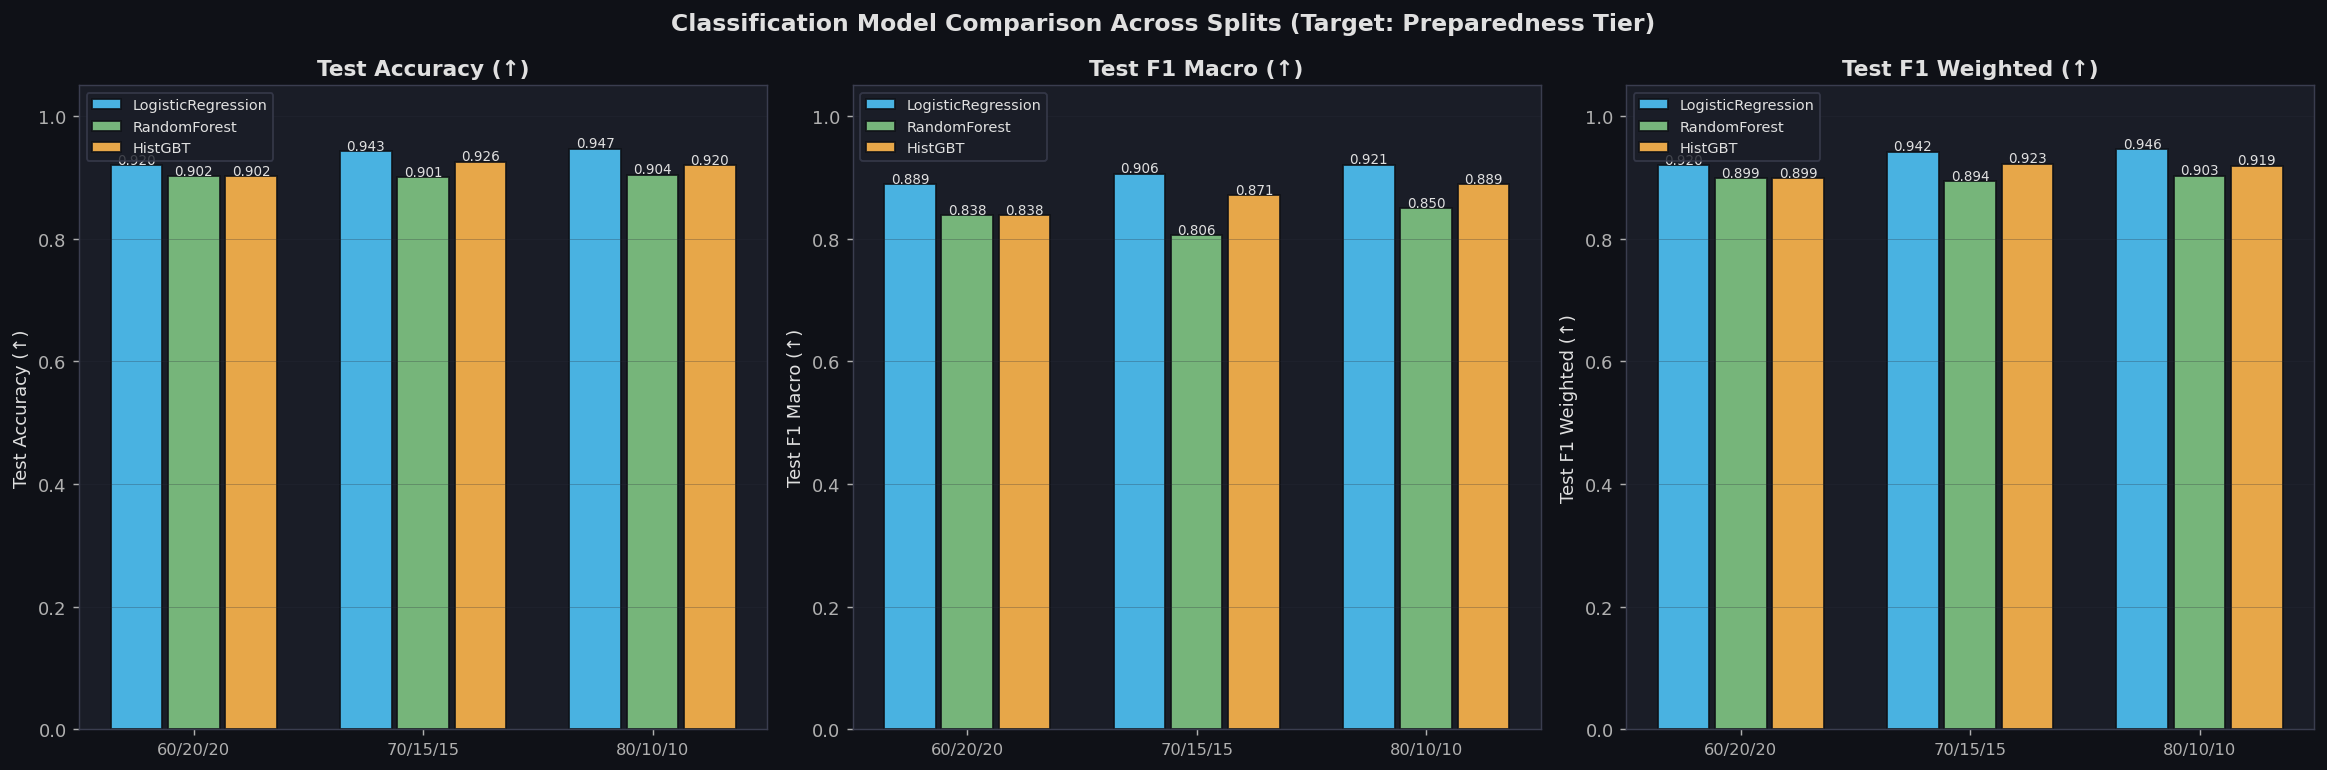

In [8]:
# ── Classification comparison ──
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("Classification Model Comparison Across Splits (Target: Preparedness Tier)", fontsize=13, fontweight="bold")

metrics_cls = [
    ("test_accuracy",    "Test Accuracy (↑)"),
    ("test_f1_macro",    "Test F1 Macro (↑)"),
    ("test_f1_weighted", "Test F1 Weighted (↑)"),
]

model_names_cls = ["LogisticRegression","RandomForest","HistGBT"]

for ax, (metric, ylabel) in zip(axes, metrics_cls):
    for j, (model_name, color) in enumerate(zip(model_names_cls, ["#4FC3F7","#81C784","#FFB74D"])):
        vals = [cls_res[(cls_res["model"]==model_name) & (cls_res["split"]==sp)][metric].values[0]
                if len(cls_res[(cls_res["model"]==model_name) & (cls_res["split"]==sp)]) > 0 else 0
                for sp in split_names]
        bars = ax.bar(x_positions + j*width - width, vals, width=width*0.9,
                      color=color, label=model_name, edgecolor="#0f1117", alpha=0.9)
        for bar, val in zip(bars, vals):
            ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.002,
                    f"{val:.3f}", ha="center", fontsize=7.5, color="#e0e0e0")
    
    ax.set_xticks(x_positions)
    ax.set_xticklabels(["60/20/20","70/15/15","80/10/10"], fontsize=9)
    ax.set_ylabel(ylabel); ax.set_title(ylabel, fontweight="bold")
    ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)
    ax.set_ylim(0, 1.05)

plt.tight_layout()
plt.savefig("../notebooks/fig_13_classification_comparison.png", dpi=130, bbox_inches="tight", facecolor="#0f1117")
plt.show()


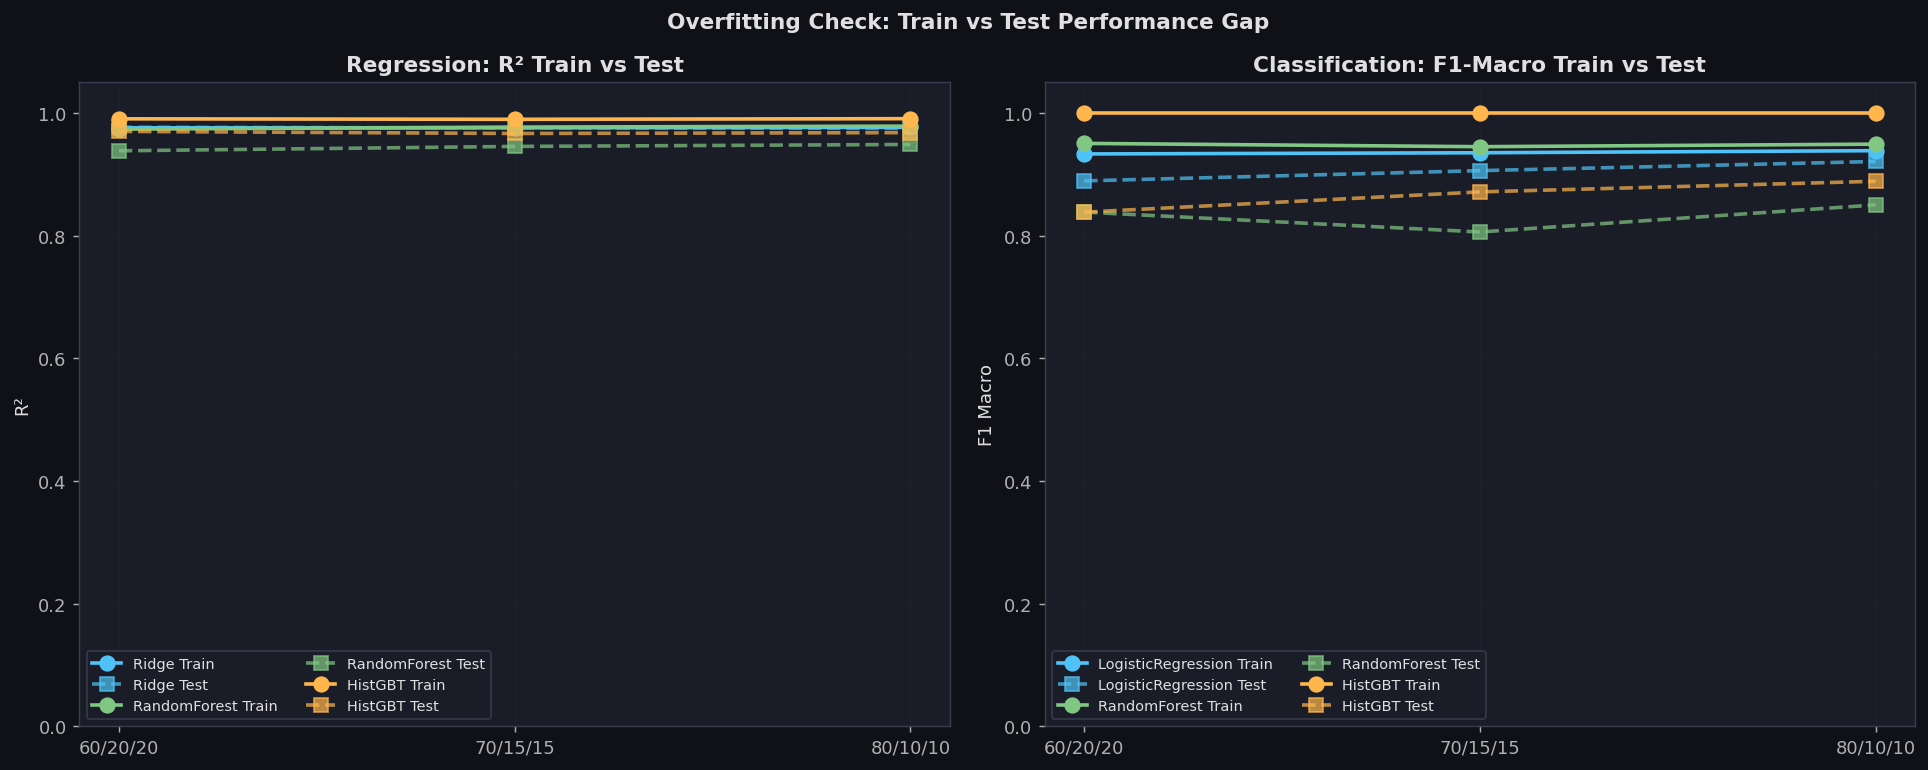

In [9]:
# ── Train vs Test gap (overfitting check) ──
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle("Overfitting Check: Train vs Test Performance Gap", fontsize=12, fontweight="bold")

# Regression: R² train vs test
ax = axes[0]
for model_name, color in zip(model_names_reg, ["#4FC3F7","#81C784","#FFB74D"]):
    subset = reg_res[reg_res["model"]==model_name]
    ax.plot(["60/20/20","70/15/15","80/10/10"], subset["train_r2"].values,
            marker="o", color=color, linestyle="-", linewidth=2, markersize=8, label=f"{model_name} Train")
    ax.plot(["60/20/20","70/15/15","80/10/10"], subset["test_r2"].values,
            marker="s", color=color, linestyle="--", linewidth=2, markersize=8, alpha=0.7, label=f"{model_name} Test")
ax.set_ylabel("R²"); ax.set_title("Regression: R² Train vs Test", fontweight="bold")
ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.3); ax.set_ylim(0, 1.05)

# Classification: F1 train vs test
ax2 = axes[1]
for model_name, color in zip(model_names_cls, ["#4FC3F7","#81C784","#FFB74D"]):
    subset = cls_res[cls_res["model"]==model_name]
    ax2.plot(["60/20/20","70/15/15","80/10/10"], subset["train_f1_macro"].values,
             marker="o", color=color, linestyle="-", linewidth=2, markersize=8, label=f"{model_name} Train")
    ax2.plot(["60/20/20","70/15/15","80/10/10"], subset["test_f1_macro"].values,
             marker="s", color=color, linestyle="--", linewidth=2, markersize=8, alpha=0.7, label=f"{model_name} Test")
ax2.set_ylabel("F1 Macro"); ax2.set_title("Classification: F1-Macro Train vs Test", fontweight="bold")
ax2.legend(fontsize=8, ncol=2); ax2.grid(alpha=0.3); ax2.set_ylim(0, 1.05)

plt.tight_layout()
plt.savefig("../notebooks/fig_14_train_test_gap.png", dpi=130, bbox_inches="tight", facecolor="#0f1117")
plt.show()


## 6. Deep Dive -- Best Model Evaluation

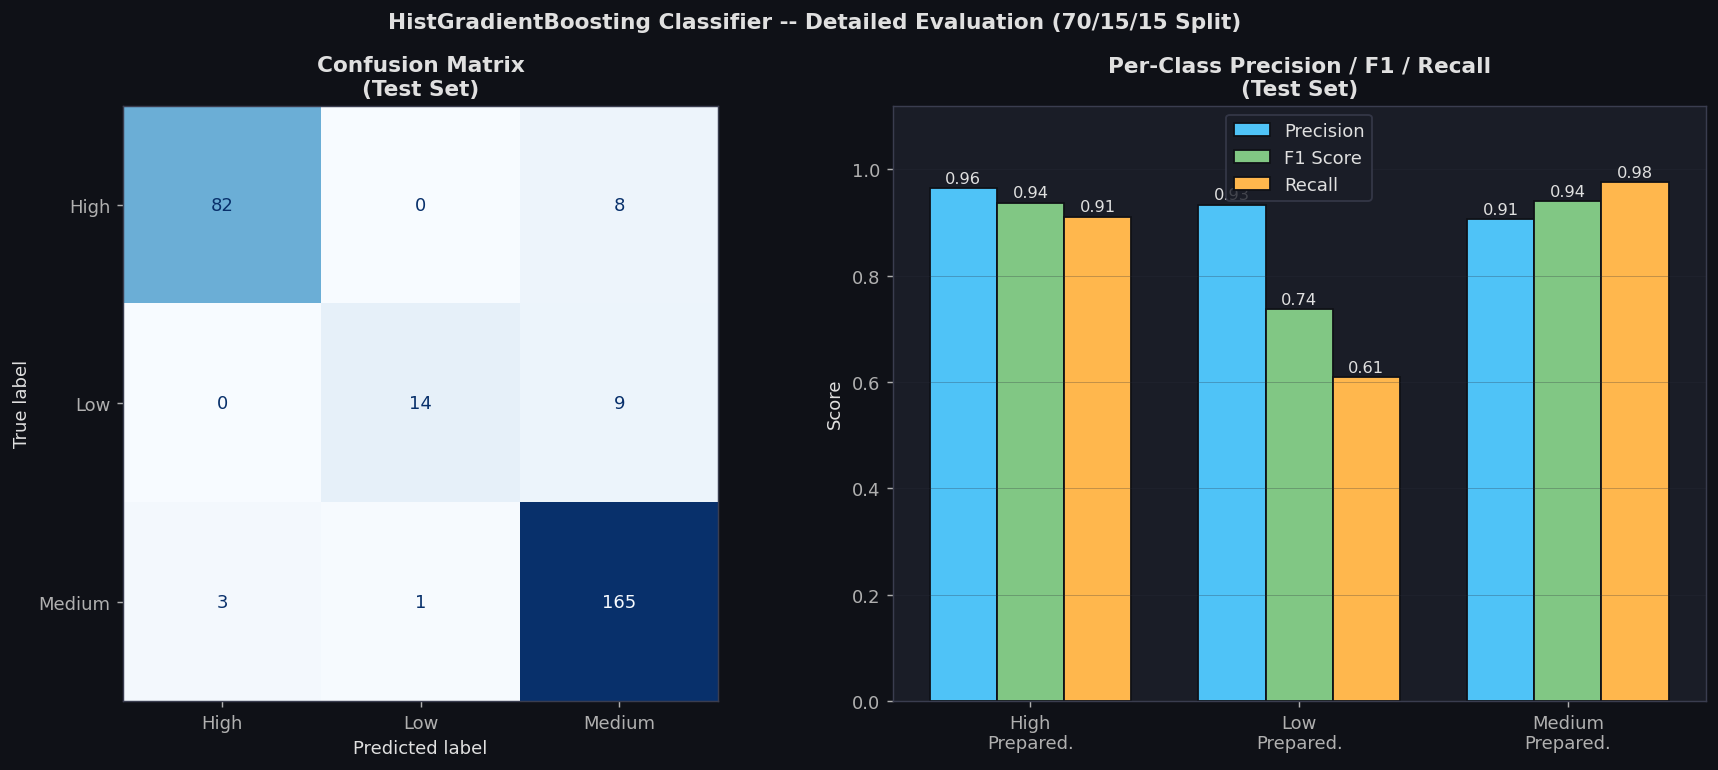

              precision    recall  f1-score   support

        High       0.96      0.91      0.94        90
         Low       0.93      0.61      0.74        23
      Medium       0.91      0.98      0.94       169

    accuracy                           0.93       282
   macro avg       0.93      0.83      0.87       282
weighted avg       0.93      0.93      0.92       282



In [10]:
# Use 70/15/15 split as primary
(X_train, X_val, X_test,
 y_r_train, y_r_val, y_r_test,
 y_c_train, y_c_val, y_c_test) = make_splits(X, y_reg, y_cls_enc, **SPLIT_CONFIGS["split_70_15_15"])

# Train best classifer (HistGBT) for detailed evaluation
best_cls = build_classification_models()["HistGBT"]
best_cls.fit(X_train, y_c_train)
y_pred_cls = best_cls.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("HistGradientBoosting Classifier -- Detailed Evaluation (70/15/15 Split)", fontsize=12, fontweight="bold")

# Confusion matrix
cm = confusion_matrix(y_c_test, y_pred_cls)
disp = ConfusionMatrixDisplay(cm, display_labels=le.classes_)
disp.plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion Matrix\n(Test Set)", fontweight="bold")
axes[0].set_facecolor("#1a1d27")

# Per-class F1 bar chart
report = classification_report(y_c_test, y_pred_cls, target_names=le.classes_, output_dict=True)
classes = le.classes_
f1_vals = [report[c]["f1-score"] for c in classes]
prec_vals = [report[c]["precision"] for c in classes]
rec_vals = [report[c]["recall"] for c in classes]

x_ = np.arange(len(classes))
w_ = 0.25
axes[1].bar(x_ - w_, prec_vals, width=w_, color="#4FC3F7", label="Precision", edgecolor="#0f1117")
axes[1].bar(x_,     f1_vals,   width=w_, color="#81C784", label="F1 Score",  edgecolor="#0f1117")
axes[1].bar(x_ + w_, rec_vals, width=w_, color="#FFB74D", label="Recall",    edgecolor="#0f1117")

for i, (p, f, r) in enumerate(zip(prec_vals, f1_vals, rec_vals)):
    axes[1].text(i - w_, p + 0.01, f"{p:.2f}", ha="center", fontsize=9, color="#e0e0e0")
    axes[1].text(i,       f + 0.01, f"{f:.2f}", ha="center", fontsize=9, color="#e0e0e0")
    axes[1].text(i + w_, r + 0.01, f"{r:.2f}", ha="center", fontsize=9, color="#e0e0e0")

axes[1].set_xticks(x_)
axes[1].set_xticklabels([f"{c}\nPrepared." for c in classes])
axes[1].set_ylabel("Score"); axes[1].set_ylim(0, 1.12)
axes[1].set_title("Per-Class Precision / F1 / Recall\n(Test Set)", fontweight="bold")
axes[1].legend(); axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("../notebooks/fig_15_confusion_matrix.png", dpi=130, bbox_inches="tight", facecolor="#0f1117")
plt.show()
print(classification_report(y_c_test, y_pred_cls, target_names=le.classes_))


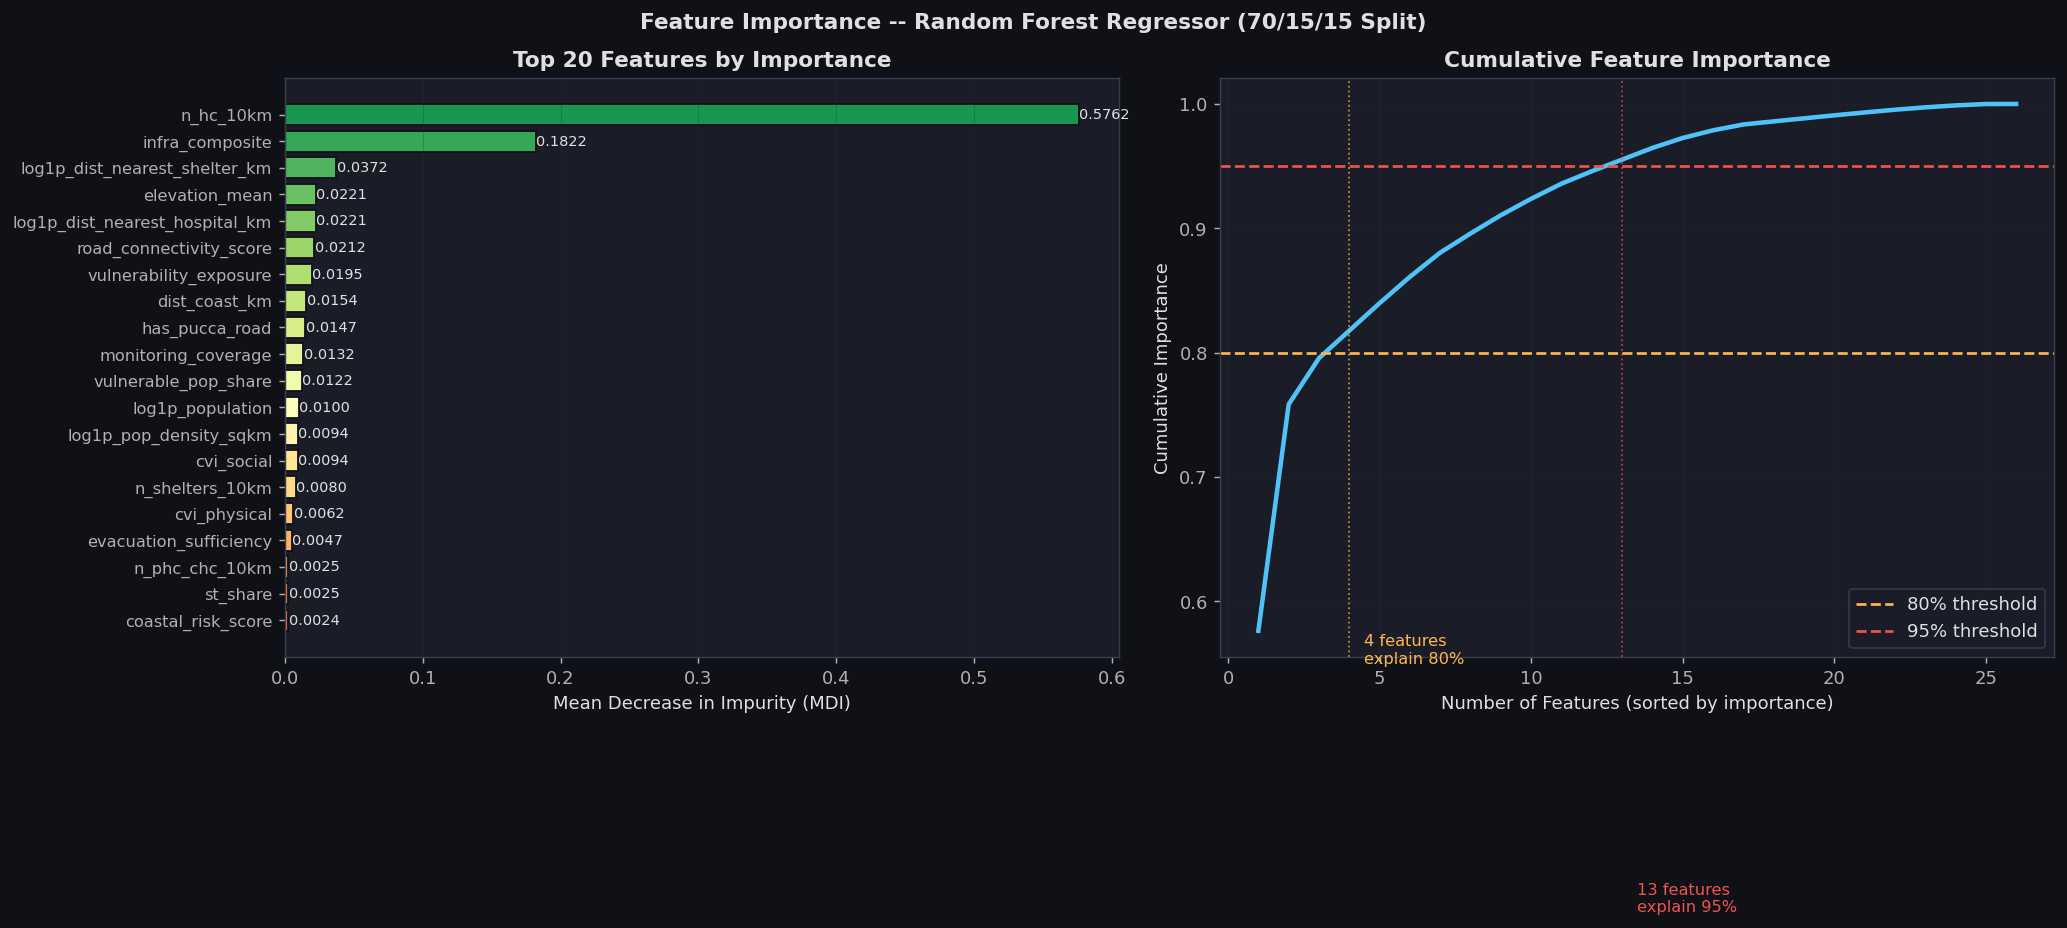

In [11]:
# Feature importance -- RandomForest (has native .feature_importances_)
best_rf_reg = build_regression_models()["RandomForest"]
best_rf_reg.fit(X_train, y_r_train)
importances = best_rf_reg.named_steps["model"].feature_importances_
feat_imp = pd.Series(importances, index=MODEL_FEATURES).sort_values(ascending=True)

# Top 20 features
top20 = feat_imp.tail(20)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
fig.suptitle("Feature Importance -- Random Forest Regressor (70/15/15 Split)", fontsize=12, fontweight="bold")

# Left: Bar chart
colors_imp = plt.cm.RdYlGn(np.linspace(0.2, 0.9, len(top20)))
axes[0].barh(range(len(top20)), top20.values, color=colors_imp, edgecolor="#0f1117")
axes[0].set_yticks(range(len(top20)))
axes[0].set_yticklabels(top20.index, fontsize=9)
axes[0].set_xlabel("Mean Decrease in Impurity (MDI)")
axes[0].set_title("Top 20 Features by Importance", fontweight="bold")
axes[0].grid(axis="x", alpha=0.3)
for i, val in enumerate(top20.values):
    axes[0].text(val + 0.0003, i, f"{val:.4f}", va="center", fontsize=8, color="#e0e0e0")

# Right: Cumulative importance
all_sorted = feat_imp.sort_values(ascending=False)
cum_imp = np.cumsum(all_sorted.values) / all_sorted.sum()
axes[1].plot(range(1, len(cum_imp)+1), cum_imp, color="#4FC3F7", linewidth=2.5)
axes[1].axhline(0.80, color="#FFB74D", linewidth=1.5, linestyle="--", label="80% threshold")
axes[1].axhline(0.95, color="#EF5350", linewidth=1.5, linestyle="--", label="95% threshold")
n80 = np.searchsorted(cum_imp, 0.80) + 1
n95 = np.searchsorted(cum_imp, 0.95) + 1
axes[1].axvline(n80, color="#FFB74D", linewidth=1, linestyle=":", alpha=0.7)
axes[1].axvline(n95, color="#EF5350", linewidth=1, linestyle=":", alpha=0.7)
axes[1].text(n80+0.5, 0.55, f"{n80} features\nexplain 80%", color="#FFB74D", fontsize=9)
axes[1].text(n95+0.5, 0.35, f"{n95} features\nexplain 95%", color="#EF5350", fontsize=9)
axes[1].set_xlabel("Number of Features (sorted by importance)")
axes[1].set_ylabel("Cumulative Importance")
axes[1].set_title("Cumulative Feature Importance", fontweight="bold")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("../notebooks/fig_16_feature_importance.png", dpi=130, bbox_inches="tight", facecolor="#0f1117")
plt.show()


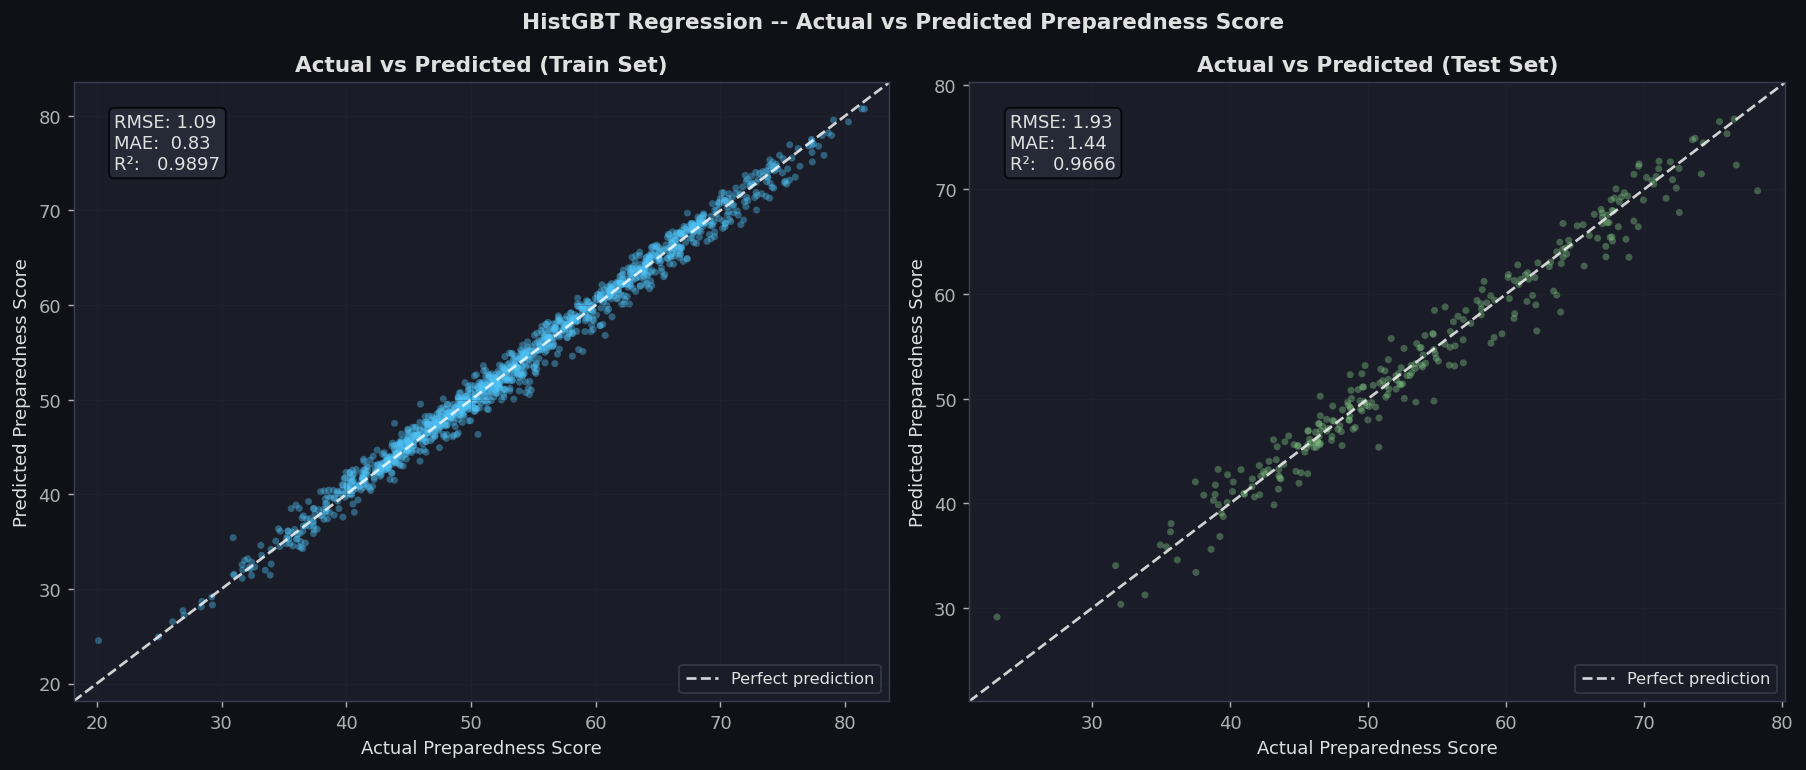

In [12]:
# Actual vs Predicted scatter (best regression model)
best_hgbt_reg = build_regression_models()["HistGBT"]
best_hgbt_reg.fit(X_train, y_r_train)
y_pred_test = best_hgbt_reg.predict(X_test)
y_pred_train = best_hgbt_reg.predict(X_train)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("HistGBT Regression -- Actual vs Predicted Preparedness Score", fontsize=12, fontweight="bold")

for ax, y_true, y_pred, label, color in [
    (axes[0], y_r_train, y_pred_train, "Train Set", "#4FC3F7"),
    (axes[1], y_r_test,  y_pred_test,  "Test Set",  "#81C784")
]:
    ax.scatter(y_true, y_pred, c=color, alpha=0.4, s=15, edgecolors="none")
    lims = [min(y_true.min(), y_pred.min())-2, max(y_true.max(), y_pred.max())+2]
    ax.plot(lims, lims, "w--", linewidth=1.5, alpha=0.8, label="Perfect prediction")
    
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    
    ax.text(0.05, 0.95, f"RMSE: {rmse:.2f}\nMAE:  {mae:.2f}\nR²:   {r2:.4f}",
            transform=ax.transAxes, va="top", fontsize=10, color="#e0e0e0",
            bbox=dict(boxstyle="round", facecolor="#2a2d3a", alpha=0.8))
    ax.set_xlabel("Actual Preparedness Score")
    ax.set_ylabel("Predicted Preparedness Score")
    ax.set_title(f"Actual vs Predicted ({label})", fontweight="bold")
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.grid(alpha=0.3); ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig("../notebooks/fig_17_actual_vs_predicted.png", dpi=130, bbox_inches="tight", facecolor="#0f1117")
plt.show()


## 7. Summary Table & W&B Dashboard Link

In [13]:
print("=" * 80)
print("  FINAL MODEL COMPARISON SUMMARY")
print("=" * 80)

# Regression
print("\n[REGRESSION -- Test RMSE / MAE / R²]")
reg_pivot = reg_res.pivot_table(
    index="model", columns="split",
    values=["test_rmse","test_mae","test_r2"], aggfunc="first"
)
print(reg_pivot.round(3).to_string())

print("\n[CLASSIFICATION -- Test Accuracy / F1 Macro]")
cls_pivot = cls_res.pivot_table(
    index="model", columns="split",
    values=["test_accuracy","test_f1_macro"], aggfunc="first"
)
print(cls_pivot.round(4).to_string())

print("\n" + "=" * 80)
print(f"  W&B Dashboard: https://wandb.ai/home → Projects → {WANDB_PROJECT}")
print("  All runs are logged with hyperparameters, metrics, and split metadata.")
print("=" * 80)


  FINAL MODEL COMPARISON SUMMARY

[REGRESSION -- Test RMSE / MAE / R²]
                   test_mae                                      test_r2                                    test_rmse                              
split        split_60_20_20 split_70_15_15 split_80_10_10 split_60_20_20 split_70_15_15 split_80_10_10 split_60_20_20 split_70_15_15 split_80_10_10
model                                                                                                                                              
HistGBT               1.397          1.439          1.480          0.970          0.967          0.968          1.861          1.929          1.935
RandomForest          1.880          1.734          1.739          0.938          0.946          0.949          2.667          2.466          2.450
Ridge                 1.212          1.229          1.296          0.977          0.976          0.975          1.639          1.646          1.712

[CLASSIFICATION -- Test Accuracy / F1 Ma